[![../img/pythonista.png](../img/pythonista.png)](https://www.pythonista.io)

# *Bootstrap* e interpretación de intervalos de confianza.

**py401 · EDA Práctico** · Pythonista® · Instructor: José Luis Chiquete · Módulo III: *Inferencia estadística*

> 🔑 **Versión con soluciones.** Solo para el instructor o para revisión posterior.

En este *notebook* se construirán intervalos de confianza con *bootstrap*, a mano y con `scipy.stats.bootstrap`, se revisará cómo interpretarlos correctamente y se presentará la consigna del Proyecto integrador.

## 🧭 Cómo usar este *notebook*.

* Ejecuta las celdas **en orden** (`Shift + Enter`).
* 🟢 **Ejercicio básico:** lo que todos deben dominar.
* 🔴 **Reto (opcional):** para quien termina antes o quiere profundizar. Si no da tiempo en clase, se puede resolver como práctica.
* Las celdas `# TU CÓDIGO AQUÍ` y *✍️ Tu respuesta* son para ti.

## 📚 Referencias.

* La generación de números aleatorios con `np.random.default_rng` se explica en [py311 · 04 Arreglos con contenido aleatorio](https://github.com/PythonistaMX/py311/blob/main/04_arreglos_con_contenido_aleatorio.ipynb) y los resúmenes con *NumPy* en [py311 · 07 Gestión y análisis de datos de *NumPy*](https://github.com/PythonistaMX/py311/blob/main/07_gestion_y_analisis_de_datos_de_numpy.ipynb).
* py311 no cubre inferencia, así que la referencia de la API es la documentación oficial: [*SciPy* · `scipy.stats`](https://docs.scipy.org/doc/scipy/reference/stats.html), [*SciPy* · `bootstrap`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.bootstrap.html) y [*statsmodels* · `proportion_confint`](https://www.statsmodels.org/stable/generated/statsmodels.stats.proportion.proportion_confint.html).

> ⚠️ **Nota:** py311 se escribió para *pandas* 2 y este curso usa *pandas* 3; si algo se ve distinto, se sigue lo que muestra este *notebook*.

### Preparación del entorno.

* La siguiente celda importará las bibliotecas, incluidos `stats` de *SciPy* y las funciones de *statsmodels* que se usarán, y definirá `DATA` y la semilla `rng`.

In [1]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA = next(os.path.join(p, "data") for p in (os.curdir, os.pardir)
            if os.path.isfile(os.path.join(p, "data", "penguins.csv")))
pd.set_option("display.max_columns", 20)
sns.set_theme(style="whitegrid")
rng = np.random.default_rng(401)
from scipy import stats
from statsmodels.stats.proportion import proportion_confint
from statsmodels.stats.weightstats import DescrStatsW

**¿Por qué este paso?** Se parte del archivo limpio de la sesión 2 para no repetir la limpieza; si no existe (por ejemplo, en un *Codespace* nuevo), se regenera con los mismos pasos mínimos. `titanic` se usará para proporciones y para un ejemplo de datos muy asimétricos.

* La siguiente celda leerá `penguins_limpio.csv` (o lo regenerará desde `penguins.csv` si no existe) y `titanic.csv`.

In [2]:
ruta_limpio = os.path.join(DATA, "penguins_limpio.csv")
medidas = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
if not os.path.isfile(ruta_limpio):
    (
        pd.read_csv(os.path.join(DATA, "penguins.csv"))
        .assign(sex=lambda d: d["sex"].str.title())
        .dropna(subset=medidas, how="all")
        .to_csv(ruta_limpio, index=False)
    )
pinguinos = pd.read_csv(ruta_limpio)
titanic = pd.read_csv(os.path.join(DATA, "titanic.csv"))
pinguinos.shape, titanic.shape

((342, 7), (891, 15))

### Objetos de los *notebooks* anteriores.

Este *notebook* es independiente: la siguiente celda vuelve a crear lo que se necesita de los *notebooks* anteriores.

* La siguiente celda definirá `masa_gentoo` y `tarifas`, que se usaron en `16_distribucion_muestral.ipynb` y `17_error_estandar_e_intervalos_de_confianza.ipynb`.

In [3]:
masa_gentoo = pinguinos.loc[pinguinos["species"] == "Gentoo", "body_mass_g"].dropna()
tarifas = titanic["fare"].to_numpy()
len(masa_gentoo), len(tarifas)

(123, 891)

---
## 1. *Bootstrap* (25 min).

El *bootstrap* estima la distribución muestral **sin fórmula**: trata la muestra como si fuera la población y la **remuestrea con reemplazo** muchas veces, calculando el estadístico en cada remuestra.

1. Remuestrear *n* valores con reemplazo de la muestra original.
2. Calcular el estadístico (media, mediana, diferencia…).
3. Repetir miles de veces; la dispersión de esos valores aproxima el error estándar y sus percentiles 2.5% y 97.5% dan un IC del 95% (**método percentil**).

* La siguiente celda hará un *bootstrap* a mano de la media de los Gentoo con 9,999 remuestras.

In [4]:
valores_gentoo = masa_gentoo.to_numpy()
remuestras = rng.choice(valores_gentoo, size=(9999, len(valores_gentoo)), replace=True)
medias_boot = remuestras.mean(axis=1)
round(float(medias_boot.std(ddof=1)), 1), np.percentile(medias_boot, [2.5, 97.5]).round(1)

(45.1, array([4988.4, 5164. ]))

**Interpretación:** el EE *bootstrap* (≈ 45 g) coincide con el de la fórmula (45.5 g), y el IC percentil (≈ 4,988 a 5,164 g) con el IC *t*. Cuando la fórmula es válida, el *bootstrap* la reproduce; su valor está en los casos en que no hay fórmula.

* La siguiente celda dibujará la distribución *bootstrap* con el intervalo percentil.

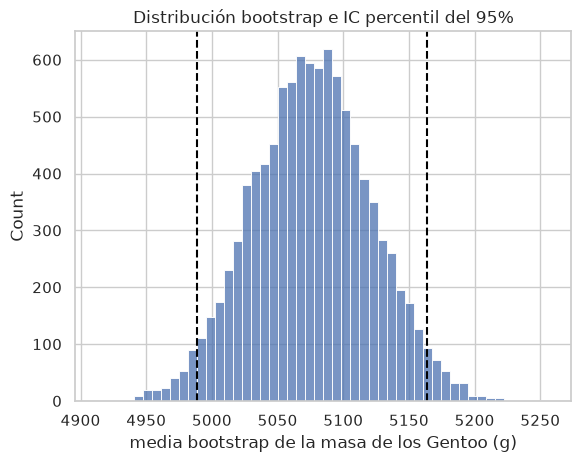

In [5]:
ax = sns.histplot(medias_boot, bins=50)
for limite in np.percentile(medias_boot, [2.5, 97.5]):
    ax.axvline(limite, color="black", linestyle="--")
ax.set(xlabel="media bootstrap de la masa de los Gentoo (g)", title="Distribución bootstrap e IC percentil del 95%")
plt.show()

**Interpretación:** la distribución *bootstrap* de la media es simétrica y con forma de campana, como predice el TCL con 123 Gentoo. Las líneas punteadas marcan los percentiles 2.5 y 97.5, que son los límites del IC.

### 1.1 `scipy.stats.bootstrap`.

```
stats.bootstrap((<muestra>,), <estadistico>, n_resamples=9999, confidence_level=0.95,
                method="BCa", random_state=401)
```

Donde:
* `<muestra>` va dentro de una tupla; para dos grupos se pasa `(<grupo_a>, <grupo_b>)`.
* `<estadistico>` es una función que acepta el argumento `axis` (como `np.mean` o `np.median`).
* `method` puede ser `"percentile"`, `"basic"` o `"BCa"` (por defecto), que corrige sesgo y asimetría.
* `random_state=401` hace reproducible el resultado.

**Concepto: percentil y BCa.** El método percentil toma directamente los percentiles 2.5 y 97.5 de la distribución *bootstrap*. BCa (*bias-corrected and accelerated*) los ajusta para corregir el sesgo del estimador y el cambio de su variabilidad, con mejor cobertura cuando la distribución *bootstrap* es asimétrica.

* La siguiente celda calculará el IC *bootstrap* de la media de los Gentoo con los métodos percentil y BCa.

In [6]:
{metodo: np.round(stats.bootstrap((valores_gentoo,), np.mean, n_resamples=9999, method=metodo,
                                  random_state=401).confidence_interval, 1)
 for metodo in ["percentile", "BCa"]}

{'percentile': array([4990.4, 5164.4]), 'BCa': array([4990. , 5164.2])}

Con 123 Gentoo y una distribución casi simétrica, la fórmula *t* (≈ 4,986 a 5,166 g) y el *bootstrap* difieren en menos de 5 g en cada extremo. La ventaja del *bootstrap* aparece con estadísticos sin fórmula sencilla, como la mediana o una diferencia de medianas.

* La siguiente celda calculará un IC *bootstrap* para la **mediana** de la masa de los Gentoo.

In [7]:
ic_mediana = stats.bootstrap((valores_gentoo,), np.median, n_resamples=9999, method="percentile", random_state=401)
float(np.median(valores_gentoo)), np.round(ic_mediana.confidence_interval, 1)

(5000.0, array([4900., 5200.]))

**Interpretación:** la mediana de los Gentoo es 5,000 g, con IC de 4,900 a 5,200 g. El intervalo es más ancho que el de la media (≈ 300 contra 180 g), coherente con el ejercicio 1 de `16_distribucion_muestral.ipynb`: la mediana es menos eficiente. Sus límites son múltiplos de 50 g porque así se registraron las masas.

### 1.2 Diferencia entre dos grupos.

Para una diferencia, la función recibe dos muestras y el `axis`. Cada grupo se remuestrea **por separado**, respetando su tamaño.

* La siguiente celda definirá `diferencia_medias` y calculará el IC *bootstrap* de la diferencia de masa media entre machos y hembras Gentoo.

In [8]:
def diferencia_medias(a, b, axis=-1):
    return np.mean(a, axis=axis) - np.mean(b, axis=axis)

gentoo = pinguinos[pinguinos["species"] == "Gentoo"]
machos_gentoo = gentoo.loc[gentoo["sex"] == "Male", "body_mass_g"].to_numpy()
hembras_gentoo = gentoo.loc[gentoo["sex"] == "Female", "body_mass_g"].to_numpy()
ic_diferencia = stats.bootstrap((machos_gentoo, hembras_gentoo), diferencia_medias, n_resamples=9999,
                                method="percentile", random_state=401)
round(float(diferencia_medias(machos_gentoo, hembras_gentoo)), 1), np.round(ic_diferencia.confidence_interval, 1)

(805.1, array([698.9, 909.9]))

**Interpretación:** los machos Gentoo pesan en promedio 805 g más que las hembras, con IC de ≈ 699 a 910 g. El intervalo está lejos de 0: la diferencia no es atribuible a la variación muestral. Este es el formato recomendado para reportar una comparación: **diferencia + IC**, antes que un valor *p* (sesión 6).

**Advertencia:** el *bootstrap* no crea información. Supone que la muestra representa bien a la población y, con muestras pequeñas o asimétricas, también **subcubre**. No corrige un sesgo de selección.

**💡 Ideas clave de la sección 1:**
* El *bootstrap* remuestrea con reemplazo para aproximar la distribución muestral de **cualquier** estadístico.
* `scipy.stats.bootstrap`: percentil o BCa, con `random_state` para reproducir.
* No crea información: no corrige sesgos ni rescata muestras pequeñas y muy asimétricas.

### 🟢 Ejercicio 1 · Mediana de la aleta de los Chinstrap.

Calcula un IC *bootstrap* del 95% (percentil, `random_state=401`) para la **mediana** de `flipper_length_mm` de los Chinstrap. Compáralo con el IC *t* de la media. ¿Por qué el intervalo de la mediana tiene límites "redondos"?

**🎯 Objetivo:** usar `scipy.stats.bootstrap` con la mediana y compararla con la media. **Qué se espera aprender:** a reconocer cómo la forma de registro de los datos (enteros) afecta a la distribución *bootstrap*.

* La siguiente celda muestra una solución posible.

In [9]:
aleta_chinstrap = pinguinos.loc[pinguinos["species"] == "Chinstrap", "flipper_length_mm"].dropna().to_numpy()
ic_mediana_aleta = stats.bootstrap((aleta_chinstrap,), np.median, n_resamples=9999, method="percentile",
                                   random_state=401).confidence_interval
ic_media_aleta = DescrStatsW(aleta_chinstrap).tconfint_mean()
float(np.median(aleta_chinstrap)), np.round(ic_mediana_aleta, 1), np.round(ic_media_aleta, 1)

(196.0, array([194. , 197.5]), array([194.1, 197.5]))

**✅ Respuesta sugerida:**

La mediana es 196 mm, con IC *bootstrap* de 194 a 197.5 mm; el IC *t* de la media (195.8 mm) es casi igual, de 194.1 a 197.5 mm. Los límites de la mediana son "redondos" porque la aleta se registró en milímetros enteros: la mediana de cada remuestra solo puede ser un valor observado o el promedio de dos (de ahí el .5). La distribución *bootstrap* de la mediana es **discreta**, algo que conviene notar al reportarla.

### 🔴 Reto 1 · ¿El *bootstrap* rescata a la tarifa del Titanic?

Repite la simulación de cobertura de la sección 1.2 de `17_error_estandar_e_intervalos_de_confianza.ipynb` para la tarifa con *n* = 10, pero con el IC *bootstrap* percentil de la media (usa 300 muestras y 999 remuestras para que no tarde, con `generador = np.random.default_rng(401)`). ¿Mejora la cobertura respecto al IC *t*?

**🎯 Objetivo:** probar los límites del *bootstrap* con una simulación de cobertura. **Qué se espera aprender:** que remuestrear no sustituye a tener una muestra representativa.

* La siguiente celda muestra una solución posible.

In [10]:
generador = np.random.default_rng(401)
media_tarifa = tarifas.mean()
aciertos = 0
for _ in range(300):
    muestra = generador.choice(tarifas, size=10)
    ic = stats.bootstrap((muestra,), np.mean, n_resamples=999, method="percentile",
                         random_state=generador).confidence_interval
    aciertos += ic.low <= media_tarifa <= ic.high
float(aciertos / 300)

0.79

**✅ Respuesta sugerida:**

No mejora: la cobertura sigue cerca de 80%, igual que con el IC *t*. Con 10 tarifas, la muestra casi nunca contiene a los pocos pasajeros de tarifas muy altas que elevan la media poblacional, y el *bootstrap* solo puede remuestrear lo que hay en la muestra. Con datos tan asimétricos y *n* pequeño conviene cambiar de estimador (mediana) o de escala (logaritmo), y advertir la incertidumbre.

---
## 2. Interpretación correcta de un IC (15 min).

| Afirmación | ¿Correcta? |
|---|---|
| "El procedimiento produce intervalos que capturan la media poblacional en 95% de las muestras repetidas." | ✅ |
| "Con los datos observados, valores de la media entre 4,986 y 5,166 g son compatibles con la muestra." | ✅ (lectura práctica) |
| "Hay 95% de probabilidad de que la masa media real esté entre 4,986 y 5,166 g." | ❌ La masa media real es fija (aunque no se conozca); lo que cambia de muestra a muestra es el intervalo |
| "El 95% de los Gentoo pesa entre 4,986 y 5,166 g." | ❌ Confunde el IC de la **media** con la dispersión de los **individuos** |
| "Si dos IC se traslapan, no hay diferencia." | ❌ Pueden traslaparse y la diferencia ser significativa; se calcula el IC **de la diferencia** |
| "Un IC más estrecho siempre es mejor." | ❌ Solo si el procedimiento cumple su cobertura (sección 1.2 de `17_error_estandar_e_intervalos_de_confianza.ipynb`) |

**¿Por qué esta sección?** Los intervalos de confianza son de los conceptos peor interpretados en la práctica, incluso en artículos publicados. Un informe con buenos cálculos y malas frases transmite conclusiones falsas. La tabla resume las lecturas correctas y los errores más comunes.

**💡 Ideas clave de la sección 2:** un IC describe la incertidumbre sobre un **parámetro**, no la dispersión de los individuos; su 95% se refiere al procedimiento; para comparar grupos se calcula el IC **de la diferencia**.

### 🟢 Ejercicio 2 · Reformula.

Un compañero escribió: *"La masa media de los Gentoo es 5,076 g y hay 95% de probabilidad de que el valor real esté entre 4,986 y 5,166 g, así que casi todos los Gentoo pesan unos 5 kg."* Señala los dos errores y reescribe la frase.

**🎯 Objetivo:** detectar y corregir interpretaciones erróneas de un IC. **Qué se espera aprender:** a redactar resultados con incertidumbre en el estilo que pide el informe del proyecto.

**✅ Respuesta sugerida:**

1. La probabilidad del 95% no se refiere a la masa media real, sino al procedimiento.
2. El IC describe la incertidumbre sobre la **media**, no el peso de los individuos: los Gentoo varían con una desviación estándar de unos 500 g.

**Reescritura:** "La masa media estimada de los Gentoo es 5,076 g (IC 95%: 4,986 a 5,166 g, *n* = 123). Los individuos varían bastante más: la desviación estándar es de unos 500 g."

### 📣 Proyecto integrador: consigna.

**Consigna:** un EDA completo en un *notebook* reproducible en *Codespaces*, más un informe de hallazgos de 2 a 4 páginas (sección Markdown final o HTML/PDF exportado con `nbconvert`).

**Datasets a elegir:** `diamonds` (*Seaborn*), Adult / Census Income (UCI), Bike Sharing (UCI), Wine Quality (UCI), o uno propio **aprobado por el instructor a más tardar en la Sesión 6**. Se descargan a `data/proyecto/` con `python tools/descargar_datasets.py <clave>` (claves `diamonds`, `adult`, `bike`, `wine`); fuente, licencia y cita de cada uno en `data/DATASETS.md`.

**Requisitos mínimos:**
1. 2 o 3 preguntas de análisis.
2. Auditoría de calidad y tratamiento justificado.
3. Descripción de distribuciones y atípicos.
4. Al menos una comparación de grupos y una relación entre variables.
5. Al menos dos pruebas de hipótesis distintas (o una prueba y un *bootstrap*), con supuestos revisados y tamaño del efecto.
6. Informe con resumen ejecutivo y limitaciones.

**Productos:** el `.ipynb` ejecutado, el informe (`.html` o `.pdf`) y el enlace al repositorio de GitHub. En la sesión 7 se entrega la **plantilla** `proyecto/plantilla_proyecto_integrador.ipynb` con esta estructura ya armada.

**Qué distingue un buen Proyecto integrador:**

| Aspecto | Qué se busca |
|---|---|
| Preguntas y contexto | Preguntas claras y respondibles con los datos; fuente y sesgos posibles descritos |
| Calidad de datos | Auditoría completa; decisiones de limpieza e imputación justificadas y con su impacto medido |
| Descripción y visualización | Distribuciones, atípicos y relaciones bien descritos; gráficas efectivas y rotuladas |
| Inferencia | Pruebas adecuadas, supuestos revisados, IC o *bootstrap*, tamaño del efecto interpretado |
| Informe de hallazgos | Resumen ejecutivo claro; hallazgos en lenguaje llano con su incertidumbre; limitaciones; sin causalidad injustificada |
| Reproducibilidad | Corre de principio a fin en *Codespaces*; `requirements.txt`, semillas y estructura ordenada |

---
## 3. Ejercicio de la sesión (20 min).

### 🟢 Ejercicio 3 · Masa media de los Gentoo: fórmula *t* y *bootstrap*.

**🎯 Objetivo:** integrar en una tabla los tres métodos de la sesión. **Qué se espera aprender:** a decidir cuándo los métodos coinciden y cuál reportar.

Reporta en una tabla la masa media de los Gentoo con su IC del 95% por la fórmula *t* y por *bootstrap* (percentil y BCa, `random_state=401`), junto con el ancho de cada intervalo.

* La siguiente celda muestra una solución posible.

In [11]:
intervalos_gentoo = {"t": DescrStatsW(valores_gentoo).tconfint_mean()}
for metodo in ["percentile", "BCa"]:
    ic = stats.bootstrap((valores_gentoo,), np.mean, n_resamples=9999, method=metodo,
                         random_state=401).confidence_interval
    intervalos_gentoo[f"bootstrap {metodo}"] = (ic.low, ic.high)
pd.DataFrame(intervalos_gentoo, index=["inferior", "superior"]).T.assign(
    ancho=lambda d: d["superior"] - d["inferior"]).round(1)

,inferior,superior,ancho
t,4986.0,5166.0,180.0
bootstrap percentile,4990.4,5164.4,174.0
bootstrap BCa,4990.0,5164.2,174.2


### 🟢 Ejercicio 4 · Diferencia de medianas entre machos y hembras Gentoo.

Calcula la diferencia de **medianas** de masa entre machos y hembras Gentoo con su IC *bootstrap* percentil del 95%. ¿El intervalo incluye el 0? ¿Qué significa?

**🎯 Objetivo:** construir un IC para un estadístico sin fórmula sencilla. **Qué se espera aprender:** a leer si un IC de una diferencia incluye el 0 y qué implica.

* La siguiente celda muestra una solución posible.

In [12]:
def diferencia_medianas(a, b, axis=-1):
    return np.median(a, axis=axis) - np.median(b, axis=axis)

ic_medianas = stats.bootstrap((machos_gentoo, hembras_gentoo), diferencia_medianas, n_resamples=9999,
                              method="percentile", random_state=401).confidence_interval
float(diferencia_medianas(machos_gentoo, hembras_gentoo)), np.round(ic_medianas, 1)

(800.0, array([650., 900.]))

**✅ Respuesta sugerida:**

Los machos Gentoo tienen una masa mediana 800 g mayor que las hembras, con IC 95% de 650 a 900 g. El intervalo está lejos de 0, así que la diferencia no se explica por variación muestral. Los límites salen en múltiplos de 50 g porque las masas se registraron redondeadas (a 25 o 50 g).

### 🔴 Reto 2 · ¿Y si se mezclan las especies?

Repite el ejercicio 4 con **todos** los pingüinos (sin separar por especie) y después dentro de cada especie. ¿Por qué la diferencia global no coincide con ninguna de las diferencias por especie? ¿Cuál reportarías?

**🎯 Objetivo:** ver cómo una variable de agrupación cambia una comparación. **Qué se espera aprender:** a decidir el nivel de agregación adecuado antes de reportar una diferencia.

* La siguiente celda muestra una solución posible.

In [13]:
filas = []
grupos = [("todas", pinguinos)] + [(especie, datos) for especie, datos in pinguinos.groupby("species")]
for nombre, datos in grupos:
    machos = datos.loc[datos["sex"] == "Male", "body_mass_g"].dropna().to_numpy()
    hembras = datos.loc[datos["sex"] == "Female", "body_mass_g"].dropna().to_numpy()
    ic = stats.bootstrap((machos, hembras), diferencia_medianas, n_resamples=9999, method="percentile",
                         random_state=401).confidence_interval
    filas.append({"grupo": nombre, "diferencia": diferencia_medianas(machos, hembras), "inferior": ic.low, "superior": ic.high})
pd.DataFrame(filas).set_index("grupo").round(1)

,diferencia,inferior,superior
grupo,,,
todas,650.0,450.0,875.0
Adelie,600.0,500.0,776.2
Chinstrap,400.0,150.0,550.0
Gentoo,800.0,650.0,900.0


**✅ Respuesta sugerida:**

Con todos juntos, la diferencia es 650 g (IC 450 a 875 g); por especie es 600 g en Adelie, 400 g en Chinstrap y 800 g en Gentoo. La cifra global no es un promedio de las tres: es la diferencia entre las medianas de dos distribuciones bimodales que mezclan especies, y por eso su intervalo es más ancho. Se reportan las diferencias **por especie**, porque la especie explica gran parte de la masa y la diferencia entre sexos no es igual en todas.

### 🟢 Ejercicio 5 · Comenta los resultados.

En 3 o 4 frases: ¿coinciden la fórmula *t* y el *bootstrap* para la media de los Gentoo? ¿Por qué? ¿Qué aporta el *bootstrap* en el ejercicio 4 que no daba la fórmula?

**🎯 Objetivo:** redactar conclusiones con incertidumbre. **Qué se espera aprender:** a justificar la elección de método con los supuestos.

**✅ Respuesta sugerida:**

Sí: para la media de los Gentoo la fórmula *t* (4,986 a 5,166 g) y el *bootstrap* (≈ 4,990 a 5,164 g) prácticamente coinciden, porque *n* = 123 es grande y la distribución es casi simétrica, así que se cumplen los supuestos de la fórmula. El *bootstrap* aporta en el ejercicio 4 un intervalo para una **diferencia de medianas**, que no tiene una fórmula sencilla; además deja ver que la distribución de la mediana es discreta.

---
## ✅ Cierre.

**Hoy vimos:**
* Distribución muestral, ley de los grandes números y teorema central del límite (lento con datos muy asimétricos).
* Error estándar: la desviación estándar dividida entre la raíz cuadrada de *n*; cuadruplicar *n* reduce el EE a la mitad; estratificar reduce el EE sin aumentar *n*.
* IC *t* para la media (*SciPy* y *statsmodels*) e IC para proporciones (Wald, Wilson, Clopper-Pearson).
* La cobertura real depende de los supuestos: con datos muy asimétricos y *n* pequeño, el IC "del 95%" cubre bastante menos.
* *Bootstrap* con `scipy.stats.bootstrap`: percentil y BCa, para la media, la mediana y diferencias entre grupos.
* Cómo interpretar (y cómo no) un intervalo de confianza.

**Práctica:** terminar los ejercicios 🟢 y elegir el *dataset* del Proyecto integrador. Si es uno propio, pedir aprobación al instructor a más tardar en la Sesión 6.

**Siguiente *notebook*:** `19_logica_del_contraste.ipynb`.

<p style="text-align: center"><a rel="license" href="http://creativecommons.org/licenses/by/4.0/"><img alt="Licencia Creative Commons" style="border-width:0" src="https://i.creativecommons.org/l/by/4.0/80x15.png" /></a><br />Esta obra está bajo una <a rel="license" href="http://creativecommons.org/licenses/by/4.0/">Licencia Creative Commons Atribución 4.0 Internacional</a>.</p>
<p style="text-align: center">&copy; José Luis Chiquete Valdivieso. 2017-2026.</p>